# ITESO, Universidad Jesuita de Guadalajara

**Materia:** Análisis Estadístico Multivariable

**Profesor:** Luis Alvarado

**Actividad:** Proyecto: RSNA Knee Abnormality Detection (Kaggle). Notebook 3: interpretación del modelo

**Integrante:** Lambda Remiel Heredia Pérez (Kaggle: `hctorheredia`, GitHub: `RemiH06`)

**Fecha:** 15 de octubre de 2026

---

## Introducción

El notebook 1 midió **qué tan bien** predice el modelo; este pregunta **dónde mira**. El modelo (CoAtNet-384 v2, el del envío 0.919) recibe cada estudio como una bolsa de ventanas 2.5D (tres cortes vecinos) y las combina con una capa de atención con pesos propios por hallazgo. Para el hallazgo $j$ y la ventana $k$ de un estudio con $K$ ventanas:

$$a_{kj}=\frac{\exp\left(e_{kj}\right)}{\sum_{k'=1}^{K}\exp\left(e_{k'j}\right)},\qquad e_{kj}=\mathbf w_j^\top\tanh(\mathbf V\mathbf h_k),\qquad \mathbf z_j=\sum_{k=1}^{K}a_{kj}\,\mathbf h_k .$$

Para cada hallazgo, $a_{kj}\ge0$ y $\sum_k a_{kj}=1$: **los pesos de atención son una función de masa de probabilidad sobre los cortes del estudio**. Eso permite tratarlos con las herramientas de la materia: marginales (cuánta masa cae en cada grupo de series), comparación contra una distribución de referencia (la uniforme), entropía como medida de concentración y pruebas entre grupos (estudios positivos contra negativos).

Se evaluaron **todas** las ventanas posibles de los 58 estudios gold (unas 60 por estudio, en lugar de las 24 de la validación). Al final, Grad-CAM localiza dentro del corte más atendido la región que empuja la predicción.

**Advertencia de interpretación.** La atención dice qué ventanas pesan en el promedio, no por qué. Es evidencia de dónde mira el modelo, no una explicación causal.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RES = ROOT / "results"
T = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
     "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
ES = dict(zip(T, ["LCA", "LCM", "Menisco med.", "Menisco lat.", "OA medial", "OA lateral",
                  "OA patelofem.", "Derrame", "Sinovitis", "Q. Baker", "Contusión", "Fractura"]))
SLOTS = ["Sagital FS", "Sagital no-FS", "Coronal FS", "Coronal no-FS", "Axial"]
SIZES = [18, 14, 12, 8, 12]
EDGES = np.cumsum([0] + SIZES)

AZUL, NARANJA, AQUA, ROJO, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#e34948", "#898781"
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#86b6ef", "#1c5cab", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", [AZUL, "#f0efec", ROJO])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "font.size": 9,
                     "axes.titlesize": 10, "axes.titleweight": "bold"})

z = np.load(RES / "attention_v2.npz")
ids, centers, attn, probs = z["ids"], z["centers"], z["attn"], z["probs"]
tr = pd.read_csv(ROOT / "data" / "train.csv").set_index("StudyInstanceUID")
Y = tr.loc[ids, T].astype(int).values
valid = centers >= 0
print(f"{len(ids)} estudios gold | ventanas por estudio: mediana {np.median(valid.sum(1)):.0f}, "
      f"rango {valid.sum(1).min()} a {valid.sum(1).max()}")
print("Comprobación: la atención de cada hallazgo suma 1 en cada estudio:",
      np.allclose(attn.sum(1), 1, atol=1e-4))

58 estudios gold | ventanas por estudio: mediana 62, rango 62 a 62
Comprobación: la atención de cada hallazgo suma 1 en cada estudio: True


## 1. Distribución marginal de la atención por grupo de series

Cada ventana pertenece a una de las 5 ranuras del corpus según su corte central. Sumando la masa de atención dentro de cada ranura se obtiene, para cada estudio $i$ y hallazgo $j$, la **marginal** $m_{ij}(s)=\sum_{k\in s}a_{kj}$, con $\sum_s m_{ij}(s)=1$. Se promedia sobre los 58 estudios.

Las ranuras no tienen el mismo tamaño (18, 14, 12, 8 y 12 cortes), así que una atención uniforme ya daría más masa a la ranura sagital FS. La referencia justa es la masa que recibiría cada ranura si la atención fuera uniforme, $u_i(s)=K_i(s)/K_i$, igual que en una prueba de independencia se compara contra la frecuencia esperada. Se reporta el cociente **observado / uniforme** (*lift*): mayor que 1 significa que el hallazgo mira esa ranura más de lo que le tocaría por tamaño.

Masa esperada con atención uniforme: {'Sagital FS': 0.274, 'Sagital no-FS': 0.226, 'Coronal FS': 0.194, 'Coronal no-FS': 0.129, 'Axial': 0.177}


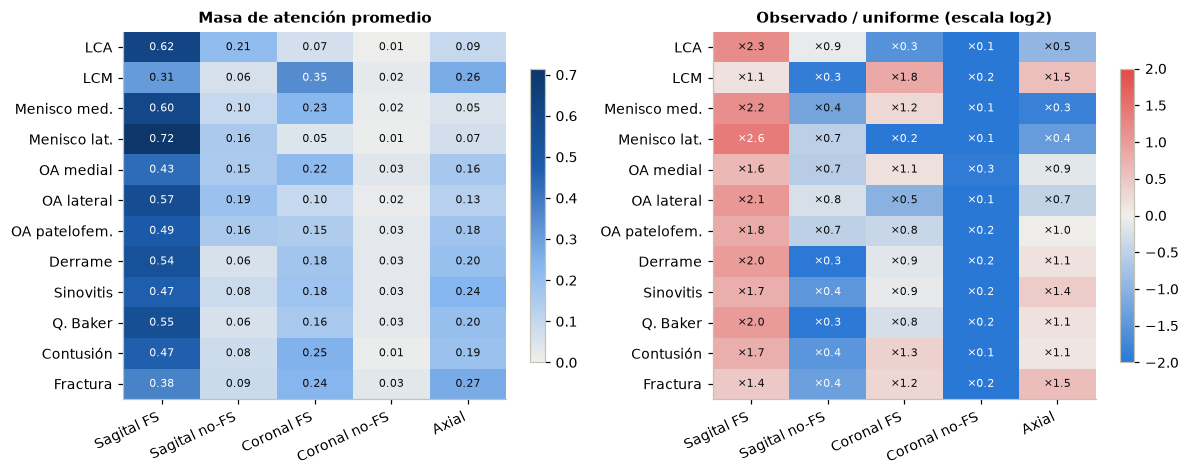

In [2]:
slot_of = np.searchsorted(EDGES, np.where(valid, centers, 0), side="right") - 1
masa = np.zeros((len(ids), 5, 12)); unif = np.zeros((len(ids), 5))
for s in range(5):
    en_s = valid & (slot_of == s)
    masa[:, s] = (attn * en_s[..., None]).sum(1)
    unif[:, s] = en_s.sum(1) / valid.sum(1)
M = pd.DataFrame(masa.mean(0).T, index=[ES[t] for t in T], columns=SLOTS)
U = pd.Series(unif.mean(0), index=SLOTS)
lift = M / U
print("Masa esperada con atención uniforme:", U.round(3).to_dict())

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, data, titulo, cmap, kw in [(axs[0], M, "Masa de atención promedio", SEQ, dict(vmin=0, vmax=M.values.max())),
                                   (axs[1], np.log2(lift), "Observado / uniforme (escala log2)", DIV, dict(vmin=-2, vmax=2))]:
    im = ax.imshow(data.values, cmap=cmap, aspect="auto", **kw)
    ax.set_xticks(range(5), SLOTS, rotation=25, ha="right"); ax.set_yticks(range(12), M.index); ax.grid(False)
    for i in range(12):
        for s in range(5):
            v = M.iloc[i, s] if ax is axs[0] else lift.iloc[i, s]
            txt = f"{v:.2f}" if ax is axs[0] else f"×{v:.1f}"
            dark = (M.iloc[i, s] > 0.45 * M.values.max()) if ax is axs[0] else abs(np.log2(v)) > 1.3
            ax.text(s, i, txt, ha="center", va="center", fontsize=7.5, color="white" if dark else "#0b0b0b")
    ax.set_title(titulo); fig.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()

**Interpretación.** La ranura sagital con supresión de grasa domina para los 12 hallazgos (entre 1.4 y 2.6 veces lo que le tocaría por tamaño), y la coronal sin supresión casi se ignora (0.1 a 0.3 veces). Es razonable: la secuencia sagital FS muestra a la vez líquido, edema y casi todas las estructuras, y es la que los radiólogos leen primero.

Lo interesante son las desviaciones, porque coinciden con la anatomía:

- **LCA** concentra su masa en sagital (×2.3): el ligamento cruzado anterior corre de adelante hacia atrás y se ve completo en cortes sagitales.
- **LCM** es el único hallazgo que mira más el **coronal FS** (×1.8) y el **axial** (×1.5) que el sagital: el ligamento colateral medial está en el costado de la rodilla y en sagital apenas aparece.
- **Fractura** y **sinovitis** suben en axial (×1.5 y ×1.4), donde se ven la rótula, el receso suprapatelar y el contorno de los huesos en corte transversal.

Nadie le dijo al modelo qué secuencia sirve para qué: lo aprendió de las etiquetas.

## 2. ¿Qué tan concentrada está la atención?

Para medir si un hallazgo mira pocos cortes o reparte la atención, se usa la **entropía normalizada** de su distribución sobre las $K$ ventanas:

$$\tilde H_{ij}=\frac{-\sum_k a_{kj}\ln a_{kj}}{\ln K_i}\in[0,1].$$

Vale 1 si la atención es uniforme y 0 si toda la masa cae en una sola ventana. También se reporta $1/\sum_k a_{kj}^2$, el **número efectivo de ventanas**: cuántas ventanas igual de pesadas darían la misma concentración.

,entropía normalizada (mediana),ventanas efectivas (mediana),peso máximo (mediana)
Menisco med.,0.681,11.109000,0.157
Menisco lat.,0.690,11.354000,0.190
Q. Baker,0.773,15.906000,0.124
Contusión,0.784,17.591000,0.106
LCA,0.786,17.815001,0.115
Derrame,0.802,21.049999,0.092
LCM,0.839,21.739000,0.098
OA lateral,0.855,23.629999,0.097
Sinovitis,0.870,27.902000,0.073
Fractura,0.879,28.046000,0.075


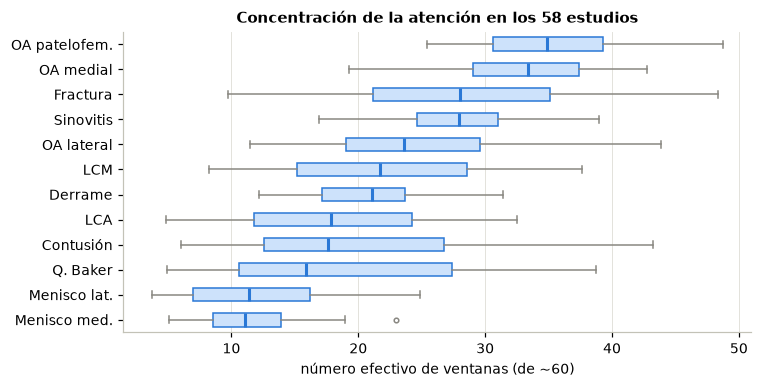

In [3]:
A = np.where(valid[..., None], attn, np.nan)
Hn = -np.nansum(A * np.log(np.clip(A, 1e-12, None)), 1) / np.log(valid.sum(1))[:, None]
neff = 1 / np.nansum(A ** 2, 1)
conc = pd.DataFrame({"entropía normalizada (mediana)": np.median(Hn, 0),
                     "ventanas efectivas (mediana)": np.median(neff, 0),
                     "peso máximo (mediana)": np.median(np.nanmax(A, 1), 0)},
                    index=[ES[t] for t in T]).sort_values("entropía normalizada (mediana)")
display(conc.round(3))

orden = [T[[ES[t] for t in T].index(n)] for n in conc.index]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.boxplot([neff[:, T.index(t)] for t in orden], orientation="horizontal", widths=0.55, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=AZUL), medianprops=dict(color=AZUL, lw=2),
           whiskerprops=dict(color=GRIS), capprops=dict(color=GRIS), flierprops=dict(marker="o", ms=3, mec=GRIS))
ax.set_yticks(range(1, 13), conc.index); ax.set_xlabel("número efectivo de ventanas (de ~60)")
ax.set_title("Concentración de la atención en los 58 estudios"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Interpretación.** Los **meniscos** son los hallazgos más focalizados (unas 11 ventanas efectivas de 62): una ruptura de menisco es una lesión pequeña que solo aparece en unos cuantos cortes. En el otro extremo, **OA medial y patelofemoral** reparten la atención en más de 30 ventanas: la artrosis es un desgaste difuso del cartílago a lo largo de toda la articulación. El orden de la tabla va de lesiones focales (meniscos, quiste de Baker, contusión, LCA) a cambios difusos (sinovitis, OA), que es lo que se esperaría clínicamente.

## 3. ¿Mira distinto cuando el hallazgo está presente?

Si la atención busca la lesión, en un estudio positivo debería concentrarse en ella; en uno negativo no hay nada que encontrar y puede repartirse. Se compara el peso máximo $\max_k a_{kj}$ entre estudios positivos y negativos de cada hallazgo con la **prueba de Mann-Whitney**, la misma estadística que define el AUC: $\widehat{\text{AUC}}=U/(n_1n_0)$ es aquí la probabilidad de que un positivo tenga la atención más concentrada que un negativo.

In [4]:
pmax = np.nanmax(A, 1)
filas = []
for j, t in enumerate(T):
    pos, neg = pmax[Y[:, j] == 1, j], pmax[Y[:, j] == 0, j]
    U_, p = stats.mannwhitneyu(pos, neg, alternative="two-sided")
    filas.append((ES[t], len(pos), np.median(pos), np.median(neg), U_ / (len(pos) * len(neg)), p))
mw = pd.DataFrame(filas, columns=["hallazgo", "positivos", "peso máx. positivos", "peso máx. negativos",
                                  "P(pos > neg)", "p"]).set_index("hallazgo")
mw["significativo 5 %"] = mw.p < 0.05
display(mw.round(3))
print(f"Hallazgos con diferencia significativa al 5 %: {mw['significativo 5 %'].sum()} de 12 "
      f"(se esperarían ~0.6 por azar)")

,positivos,peso máx. positivos,peso máx. negativos,P(pos > neg),p,significativo 5 %
hallazgo,,,,,,
LCA,24,0.149,0.102,0.735,0.002,True
LCM,9,0.155,0.085,0.757,0.015,True
Menisco med.,26,0.156,0.163,0.518,0.821,False
Menisco lat.,23,0.231,0.145,0.635,0.086,False
OA medial,15,0.075,0.055,0.878,0.000,True
OA lateral,11,0.110,0.086,0.745,0.012,True
OA patelofem.,21,0.063,0.058,0.578,0.332,False
Derrame,35,0.081,0.106,0.270,0.003,True
Sinovitis,27,0.071,0.074,0.486,0.864,False


Hallazgos con diferencia significativa al 5 %: 8 de 12 (se esperarían ~0.6 por azar)


**Interpretación.** En 8 de los 12 hallazgos la concentración de la atención difiere entre positivos y negativos al 5 %, contra ~0.6 esperados por azar; con corrección de Bonferroni ($\alpha=0.05/12$) siguen en pie LCA, OA medial y derrame. En siete de ellos la atención se **concentra más cuando el hallazgo está presente** (LCA, LCM, OA medial y lateral, quiste de Baker, contusión, fractura): el modelo encuentra la lesión y se queda ahí.

El **derrame** es la excepción y va al revés ($P=0.27$): cuando hay derrame, la atención se **reparte**. Tiene sentido, porque el líquido llena la articulación y aparece en muchos cortes a la vez, así que no hay un solo lugar donde mirar. Sinovitis y menisco medial no muestran diferencia; la sinovitis es justo el hallazgo con peor etiqueta y peor AUC (notebook 1).

## 4. ¿Los hallazgos que se acompañan miran lo mismo?

En el notebook 1 los hallazgos formaron familias (degenerativa, traumática, inflamatoria) por su correlación en las etiquetas. Aquí se pregunta si el modelo también los agrupa por **dónde mira**. Para cada par de hallazgos $(j,l)$ y cada estudio se mide el traslape de sus dos distribuciones de atención con el coeficiente de Bhattacharyya,

$$BC_i(j,l)=\sum_k\sqrt{a_{kj}\,a_{kl}}\in[0,1],$$

que vale 1 si las dos distribuciones son idénticas y 0 si no comparten ninguna ventana. Se promedia sobre los 58 estudios y se compara contra la correlación $\phi$ de las etiquetas gold.

Spearman entre traslape de atención y correlación de etiquetas (66 pares): 0.09 (p = 0.466)


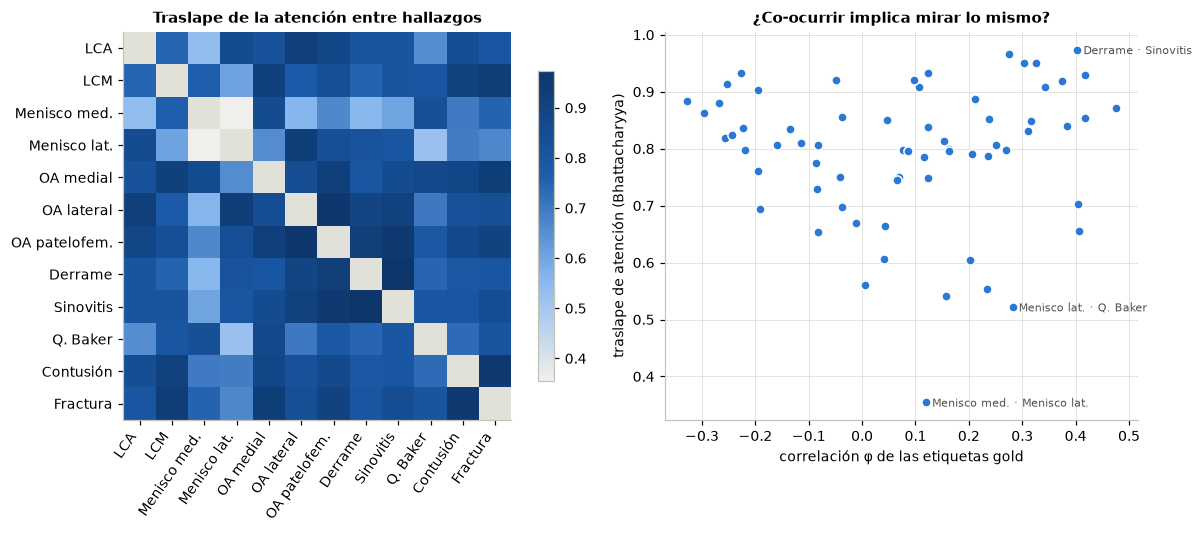

In [5]:
BC = np.zeros((12, 12))
for j in range(12):
    for l in range(12):
        BC[j, l] = np.nanmean(np.nansum(np.sqrt(A[:, :, j] * A[:, :, l]), 1))
R = pd.DataFrame(Y, columns=T).corr().values
iu = np.triu_indices(12, 1)
r = stats.spearmanr(R[iu], BC[iu])
print(f"Spearman entre traslape de atención y correlación de etiquetas (66 pares): {r.statistic:.2f} (p = {r.pvalue:.3f})")

fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
B = BC.copy(); np.fill_diagonal(B, np.nan)
im = axs[0].imshow(np.ma.masked_invalid(B), cmap=SEQ, vmin=np.nanmin(B), vmax=np.nanmax(B))
axs[0].set_facecolor("#e1e0d9")
lab = [ES[t] for t in T]
axs[0].set_xticks(range(12), lab, rotation=55, ha="right"); axs[0].set_yticks(range(12), lab); axs[0].grid(False)
axs[0].set_title("Traslape de la atención entre hallazgos"); fig.colorbar(im, ax=axs[0], shrink=0.8)
axs[1].scatter(R[iu], BC[iu], s=36, color=AZUL, edgecolor="white", linewidth=1)
for m in list(np.argsort(-BC[iu])[:1]) + list(np.argsort(BC[iu])[:2]):
    i_, j_ = iu[0][m], iu[1][m]
    axs[1].annotate(f"{ES[T[i_]]} · {ES[T[j_]]}", (R[i_, j_], BC[i_, j_]), fontsize=7, xytext=(4, -3),
                    textcoords="offset points", color="#52514e")
axs[1].set_xlabel("correlación φ de las etiquetas gold"); axs[1].set_ylabel("traslape de atención (Bhattacharyya)")
axs[1].set_title("¿Co-ocurrir implica mirar lo mismo?")
plt.tight_layout(); plt.show()

**Interpretación.** No hay relación entre que dos hallazgos se acompañen y que el modelo los busque en el mismo lugar ($\rho=0.09$, $p=0.47$). El modelo separa los hallazgos por **anatomía**, no por co-ocurrencia. El caso más claro es el par de **meniscos medial y lateral**, el de menor traslape (0.35) aunque los dos dominan la ranura sagital FS: miran cortes sagitales distintos, uno del lado interno y otro del externo de la rodilla. El mayor traslape es **derrame y sinovitis**, que sí son el mismo fenómeno visual (líquido e inflamación en la articulación).

Entonces, ¿de dónde sale la estructura de familias de las predicciones? De los rasgos compartidos $\mathbf h_k$: todos los hallazgos usan el mismo extractor, y aunque cada uno pondere ventanas distintas, el vector de rasgos de una rodilla con artrosis ya codifica todo el perfil degenerativo.

## 5. Grad-CAM: dónde dentro del corte

La atención dice qué ventana pesa; Grad-CAM dice qué región dentro de esa ventana empuja la predicción. Para el hallazgo $j$ se toma el mapa de rasgos de la última etapa de la red, $\mathbf A^{c}\in\mathbb R^{h\times w}$ por canal $c$, y se pondera cada canal por el gradiente promedio del logit:

$$\alpha_c=\frac{1}{hw}\sum_{u,v}\frac{\partial z_j}{\partial A^{c}_{uv}},\qquad L_j=\operatorname{ReLU}\Big(\sum_c\alpha_c\,\mathbf A^{c}\Big).$$

Se muestra para dos estudios gold, uno con perfil traumático y uno degenerativo, en la ventana más atendida de cada hallazgo. El mapa tiene resolución baja (12 × 12 sobre 384 px), así que marca zonas, no estructuras finas.

> Esta celda muestra imágenes de la competencia: **se borra su salida antes de subir el notebook** al repositorio público.

In [ ]:
c = np.load(RES / "attention_v2_cam.npz")
for e, uid in enumerate(c["ids"]):
    fila = list(ids).index(uid)
    fig, axs = plt.subplots(2, 6, figsize=(12, 5.4))
    for j, ax in enumerate(axs.flat):
        im = c["slices"][e, j]; cam = c["cams"][e, j]
        ax.imshow(im, cmap="gray")
        ax.imshow(cam, cmap="magma", alpha=0.45, extent=(0, im.shape[1], im.shape[0], 0), interpolation="bilinear")
        s = SLOTS[np.searchsorted(EDGES, c["centers"][e, j], side="right") - 1]
        marca = "positivo" if Y[fila, j] else "negativo"
        ax.set_title(f"{ES[T[j]]} ({marca})\np = {probs[fila, j]:.2f} · {s}", fontsize=7.5,
                     color="#0b0b0b" if Y[fila, j] else GRIS)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    fig.suptitle(f"Estudio de ejemplo {e + 1}: corte más atendido por hallazgo y su Grad-CAM", fontweight="bold")
    plt.tight_layout(); plt.subplots_adjust(hspace=0.35); plt.show()

**Interpretación.** En el estudio traumático (LCA, contusión y fractura positivos), los mapas caen donde un radiólogo buscaría: el del **LCA** en la escotadura intercondílea, por donde pasa el ligamento; el de la **contusión** dentro del cóndilo femoral, donde está el edema óseo; y el de la **fractura** en la meseta tibial. El **derrame** se localiza en los recesos de la articulación, donde se junta el líquido: el suprapatelar (arriba de la rótula) en el estudio degenerativo y los laterales en el traumático.

En los hallazgos negativos los mapas tienden a ser difusos o a caer en zonas sin relación: si no hay lesión, no hay nada que localizar y el gradiente se reparte. El caso del **LCM** en el estudio traumático es un error del modelo que el mapa delata: predice 0.94 en un estudio negativo, y su Grad-CAM es un patrón difuso, sin ninguna zona en el ligamento. Probablemente el modelo lo infiere del contexto traumático (LCA roto, contusión) más que de la imagen del ligamento, lo cual es coherente con sus correlaciones positivas, aunque débiles ($\phi\approx0.12$), con LCA, contusión y fractura. Son dos estudios, así que esto ilustra el comportamiento y no lo prueba; la evidencia cuantitativa está en las secciones 1 a 3.

## Conclusiones

1. **La atención es una distribución de probabilidad sobre los cortes**, y tratarla así permite medirla: marginales por grupo de series, comparación contra la uniforme, entropía y pruebas entre grupos.
2. **El modelo aprendió anatomía sin que se la enseñaran.** El LCA se busca en sagital, el LCM en coronal y axial, y los dos meniscos en cortes distintos. Nada de esto estaba en las etiquetas, que solo dicen "presente o ausente".
3. **La forma de la atención depende del tipo de lesión.** Las lesiones focales (meniscos, LCA, contusión) se miran en pocos cortes, y en la mayoría la atención se concentra cuando están presentes. Las difusas (artrosis) reparten la atención, y el derrame la reparte justo cuando está presente.
4. **Co-ocurrir no implica mirar lo mismo.** Las familias de hallazgos del notebook 1 no vienen de mirar las mismas ventanas sino del extractor de rasgos compartido.
5. **Los hallazgos débiles también son los menos interpretables.** La sinovitis no cambia su atención entre positivos y negativos, en línea con su etiqueta y su AUC bajos: el modelo no encontró un patrón de imagen confiable para ella.

**Limitaciones.** La atención indica qué ventanas pesan en el promedio, no causalidad. Grad-CAM tiene resolución de 12 × 12 sobre 384 px y solo se muestran dos estudios. Todo se mide sobre los mismos 58 estudios gold, con la incertidumbre que eso implica (notebook 1, Fase 4).